# Phần 3.3 — Hệ sinh thái phim lậu: ai đăng, bằng công nghệ gì, cho cộng đồng nào

Tên torrent không chỉ chứa tên phim mà còn "tự khai" rất nhiều thông tin: **nhóm/trang phát hành** (YTS, RARBG, TGx…), **codec** (x264, x265, AV1), **độ phân giải**, **dịch vụ streaming được rip** (AMZN, NF, DSNP…), **ngôn ngữ lồng tiếng** (Hindi, Dublado, Lektor PL…). Phần này tách các thông tin đó bằng biểu thức chính quy trên ~920 nghìn torrent phim (sạch) của giai đoạn ổn định 04/2021 – 09/2024.

Lưu ý: nhận diện bằng từ khóa nên có sai số; nhiều torrent không ghi đủ thông tin (nhóm "không ghi" được giữ lại để tỷ lệ trung thực). Biểu đồ lưu vào `plots/8_piracy_ecosystem/`.

In [1]:
# Tìm thư mục gốc dự án (chứa src/viz_style.py) để import phong cách biểu đồ dùng chung
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "viz_style.py").exists())
sys.path.insert(0, str(ROOT / "src"))
%matplotlib inline

## Nạp dữ liệu

In [2]:
import re

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

import viz_style as V

V.setup()
FOLDER = "8_piracy_ecosystem"
SRC = "Nguồn: MagnetDB, IMDb, TMDb; xử lý của nhóm."
P = lambda name: (V.DC / name).as_posix()
con = duckdb.connect()
t = con.execute(f"""
    SELECT t.torrent_id, t.imdb_id, t.torrent_name AS name, t.total_size, t.discovered_at_utc AS ts,
           t.quality_tier, t.implausible, m.original_language, m.title, m.start_year
    FROM read_parquet('{P('torrents_clean.parquet')}') t
    JOIN read_parquet('{P('movie_analysis.parquet')}') m USING (imdb_id)
    WHERE t.discovered_at_utc BETWEEN '2021-04-01' AND '2024-09-29'
""").df().drop_duplicates("torrent_id")
t["name"] = t["name"].fillna("")
t["q"] = t["ts"].dt.to_period("Q").dt.to_timestamp()
ok = t[~t["implausible"]].copy()
print(f"{len(ok):,} torrent phim (sạch) trong giai đoạn ổn định; {t['implausible'].sum():,} torrent giả")


def tag(series, patterns, default=None):
    """Gán nhãn theo danh sách (nhãn, regex) — nhãn đầu tiên khớp được chọn."""
    out = pd.Series(default, index=series.index, dtype=object)
    for label, rx in reversed(patterns):
        out[series.str.contains(rx, regex=True)] = label
    return out

918,863 torrent phim (sạch) trong giai đoạn ổn định; 19,023 torrent giả


## 1. Ai là người phát hành bản lậu nhiều nhất?

  wrote plots\8_piracy_ecosystem\01_release_groups_bump.png


C:\Users\admin\AppData\Local\Temp\ipykernel_20904\3699419988.py:17: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  ax.text(rank.index[-1] + pd.Timedelta(days=25), rank[b].iloc[-1], b, va="center", color=V.INK2, fontsize=9)
C:\Users\admin\AppData\Local\Temp\ipykernel_20904\3699419988.py:18: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  ax.text(rank.index[0] - pd.Timedelta(days=25), rank[b].iloc[0], b, va="center", ha="right", color=V.INK2, fontsize=9)
C:\Users\admin\AppData\Local\Temp\ipykernel_20904\3699419988.py:24: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit co

WindowsPath('D:/dulieulon/plots/8_piracy_ecosystem/01_release_groups_bump.png')

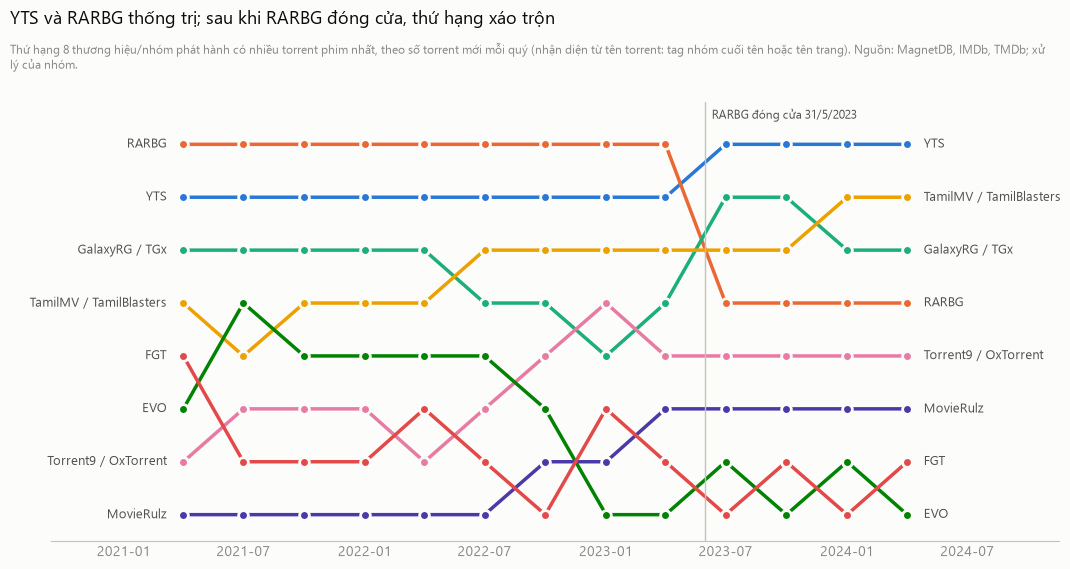

In [3]:
BRANDS = [("YTS", r"(?i)\byts\b|\[yts"), ("RARBG", r"(?i)rarbg"), ("GalaxyRG / TGx", r"(?i)galaxyrg|\btgx\b"),
          ("PSA", r"(?i)-psa\b|\bpsa\b"), ("EVO", r"(?i)-evo\b"), ("FGT", r"(?i)-fgt\b"), ("ION10", r"(?i)-ion10\b"),
          ("NNMClub", r"(?i)nnmclub|nnm-club"), ("Torrent9 / OxTorrent", r"(?i)torrent9|oxtorrent|torrent911"),
          ("TamilMV / TamilBlasters", r"(?i)tamilmv|tamilblasters"), ("MovieRulz", r"(?i)movierulz"),
          ("Cpasbien", r"(?i)cpasbien"), ("QxR", r"(?i)\bqxr\b"), ("Tigole", r"(?i)tigole")]
ok["brand"] = tag(ok["name"], BRANDS)
top8 = ok["brand"].value_counts().head(8).index.tolist()
rank = (ok[ok["brand"].isin(top8)].groupby(["q", "brand"]).size().unstack(fill_value=0)
        .rank(axis=1, ascending=False, method="first"))
rank = rank[rank.index < "2024-07-01"]
fig, ax = plt.subplots(figsize=(11, 5.8))
V.style_axes(ax, grid=None)
colors = dict(zip(top8, V.CAT))
for b in top8:
    ax.plot(rank.index, rank[b], color=colors[b], linewidth=2.5, marker="o", markersize=7,
            markeredgecolor=V.SURFACE, markeredgewidth=2)
    ax.text(rank.index[-1] + pd.Timedelta(days=25), rank[b].iloc[-1], b, va="center", color=V.INK2, fontsize=9)
    ax.text(rank.index[0] - pd.Timedelta(days=25), rank[b].iloc[0], b, va="center", ha="right", color=V.INK2, fontsize=9)
ax.axvline(pd.Timestamp("2023-05-31"), color=V.AXIS, linewidth=1)
ax.text(pd.Timestamp("2023-06-10"), 0.45, "RARBG đóng cửa 31/5/2023", color=V.INK2, fontsize=8.5, va="center")
ax.invert_yaxis()
ax.set_ylim(8.5, 0.2)
ax.set_yticks([])                                    # thứ hạng đọc qua vị trí; nhãn tên ở hai đầu
ax.set_xlim(rank.index[0] - pd.Timedelta(days=200), rank.index[-1] + pd.Timedelta(days=230))
V.titles(fig, "YTS và RARBG thống trị; sau khi RARBG đóng cửa, thứ hạng xáo trộn",
         f"Thứ hạng 8 thương hiệu/nhóm phát hành có nhiều torrent phim nhất, theo số torrent mới mỗi quý (nhận diện từ tên torrent: "
         f"tag nhóm cuối tên hoặc tên trang). {SRC}")
V.save(fig, FOLDER, "01_release_groups_bump")

**Nhận xét.** Hai "thương hiệu" thống trị suốt giai đoạn: **RARBG** (#1 cho đến 2023) và **YTS** (bản nén nhẹ, phổ biến). Sau khi RARBG đóng cửa (31/5/2023), YTS lên #1, **GalaxyRG/TGx** và **TamilMV/TamilBlasters** (phim Ấn Độ) leo hạng. Các nhóm "scene" như EVO, FGT dao động ở cuối bảng.

## 2. RARBG đóng cửa — ai lấp chỗ trống?

  wrote plots\8_piracy_ecosystem\02_rarbg_shutdown.png


  wrote plots\8_piracy_ecosystem\03_codec_share.png


  wrote plots\8_piracy_ecosystem\04_resolution_share.png


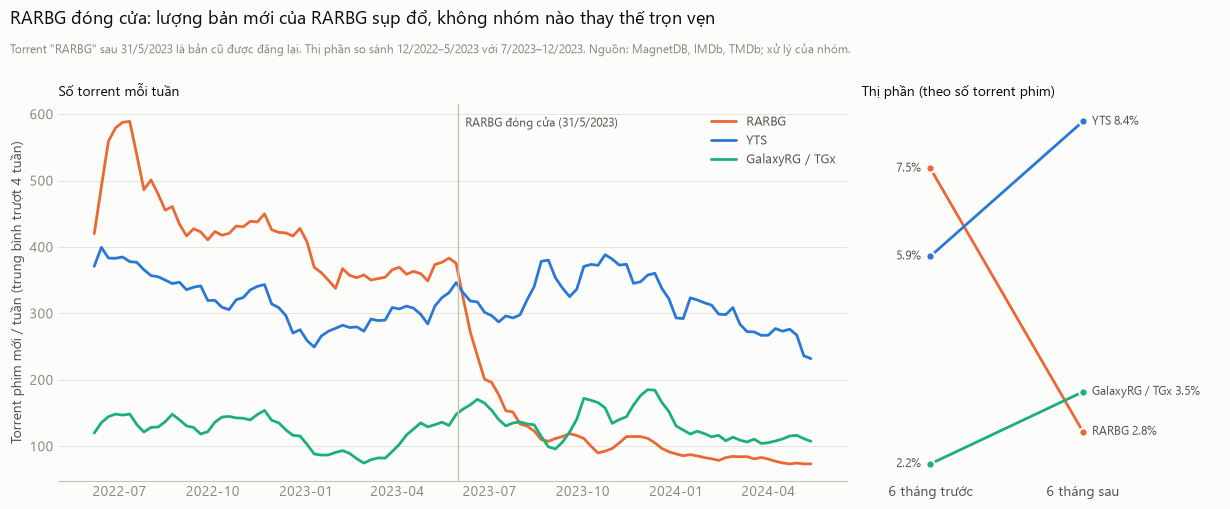

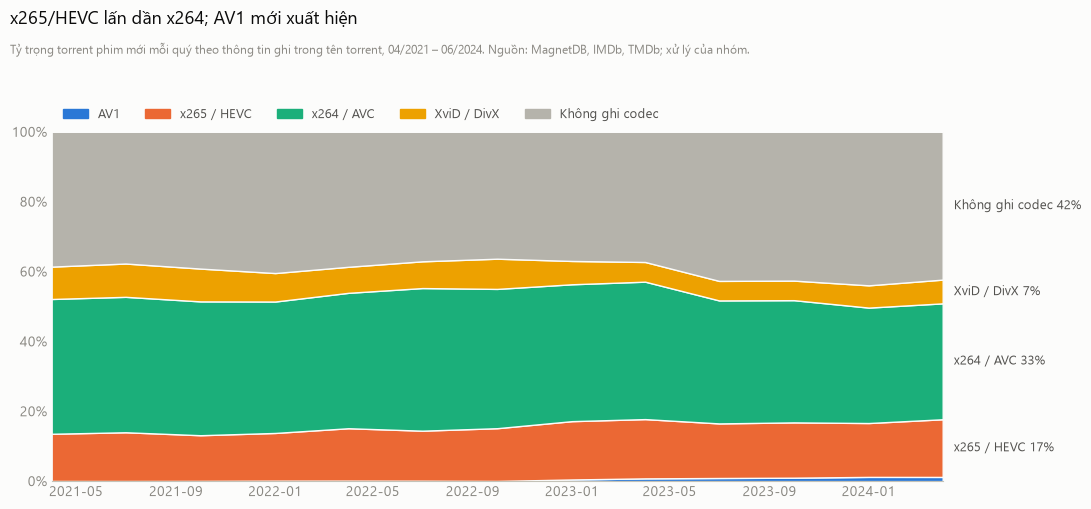

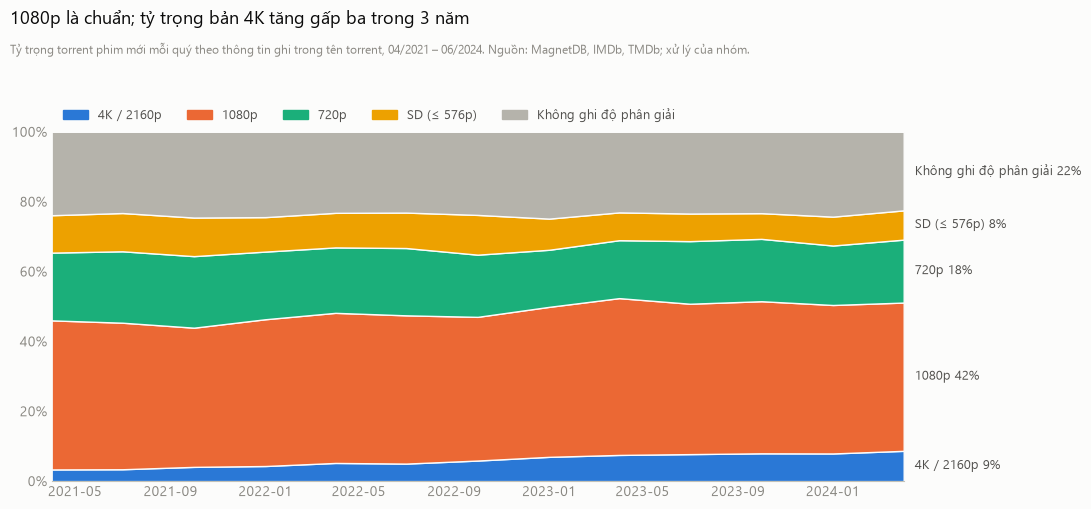

In [4]:
wk = ok.assign(w=ok["ts"].dt.to_period("W").dt.start_time)
weekly = wk.groupby(["w", "brand"]).size().unstack(fill_value=0)
weekly = weekly[(weekly.index >= "2022-06-01") & (weekly.index < "2024-05-20")]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw=dict(width_ratios=[2.2, 1]))
V.style_axes(ax)
ax.plot(weekly.index, weekly["RARBG"].rolling(4, min_periods=1).mean(), color=V.CAT[1], label="RARBG")
ax.plot(weekly.index, weekly["YTS"].rolling(4, min_periods=1).mean(), color=V.CAT[0], label="YTS")
ax.plot(weekly.index, weekly["GalaxyRG / TGx"].rolling(4, min_periods=1).mean(), color=V.CAT[2], label="GalaxyRG / TGx")
ax.axvline(pd.Timestamp("2023-05-31"), color=V.AXIS, linewidth=1)
ax.text(pd.Timestamp("2023-06-07"), ax.get_ylim()[1] * 0.97, "RARBG đóng cửa (31/5/2023)", color=V.INK2, fontsize=8.5, va="top")
ax.set_ylabel("Torrent phim mới / tuần (trung bình trượt 4 tuần)")
ax.legend(loc="upper right")
ax.set_title("Số torrent mỗi tuần", loc="left", color=V.INK, fontsize=10)
before = ok[(ok["ts"] >= "2022-12-01") & (ok["ts"] < "2023-06-01")]
after = ok[(ok["ts"] >= "2023-07-01") & (ok["ts"] < "2024-01-01")]
sb = before["brand"].fillna("Khác").value_counts(normalize=True)
sa = after["brand"].fillna("Khác").value_counts(normalize=True)
show = ["RARBG", "YTS", "GalaxyRG / TGx"]
V.style_axes(ax2, grid=None)
ax2.spines["bottom"].set_visible(False)
for b in show:
    y0, y1 = sb.get(b, 0), sa.get(b, 0)
    c = {"RARBG": V.CAT[1], "YTS": V.CAT[0], "GalaxyRG / TGx": V.CAT[2]}[b]   # cùng màu với biểu đồ bên trái
    ax2.plot([0, 1], [y0, y1], color=c, linewidth=2, marker="o", markersize=6, markeredgecolor=V.SURFACE, markeredgewidth=1.5)
    ax2.text(1.06, y1, f"{b} {y1:.1%}", va="center", color=V.INK2, fontsize=8.5)
    ax2.text(-0.06, y0, f"{y0:.1%}", va="center", ha="right", color=V.INK2, fontsize=8.5)
ax2.set_xticks([0, 1])
ax2.set_xticklabels(["6 tháng trước", "6 tháng sau"], color=V.INK2)
ax2.set_xlim(-0.45, 1.9)
ax2.set_yticks([])
ax2.set_title("Thị phần (theo số torrent phim)", loc="left", color=V.INK, fontsize=10)
V.titles(fig, "RARBG đóng cửa: lượng bản mới của RARBG sụp đổ, không nhóm nào thay thế trọn vẹn",
         f"Torrent \"RARBG\" sau 31/5/2023 là bản cũ được đăng lại. Thị phần so sánh 12/2022–5/2023 với 7/2023–12/2023. {SRC}")
V.save(fig, FOLDER, "02_rarbg_shutdown")

# ---- 03 & 04. Công nghệ: codec và độ phân giải theo quý -------------------------------------------------------------
CODEC = [("AV1", r"(?i)\bav1\b"), ("x265 / HEVC", r"(?i)x265|hevc|h\.?265"), ("x264 / AVC", r"(?i)x264|h\.?264|\bavc\b"),
         ("XviD / DivX", r"(?i)xvid|divx")]
RES = [("4K / 2160p", r"(?i)2160p|\b4k\b|\buhd\b"), ("1080p", r"(?i)1080[pi]"), ("720p", r"(?i)720p"),
       ("SD (≤ 576p)", r"(?i)480p|576p|dvdrip|xvid|\bsd\b")]
for num, (pats, title_txt, fname, unknown) in enumerate([
        (CODEC, "x265/HEVC lấn dần x264; AV1 mới xuất hiện", "03_codec_share", "Không ghi codec"),
        (RES, "1080p là chuẩn; tỷ trọng bản 4K tăng gấp ba trong 3 năm", "04_resolution_share", "Không ghi độ phân giải")], start=3):
    lab = tag(ok["name"], pats, default=unknown)
    sh = pd.crosstab(ok["q"], lab, normalize="index")
    sh = sh[sh.index < "2024-07-01"]
    order = [p[0] for p in pats] + [unknown]
    sh = sh.reindex(columns=order, fill_value=0)
    fig, ax = plt.subplots(figsize=(11, 5.2))
    V.style_axes(ax, grid=None)
    cols = V.CAT[:len(pats)] + [V.OTHER]
    ax.stackplot(sh.index, sh.T.values, colors=cols, edgecolor=V.SURFACE, linewidth=1)
    cum = sh.iloc[-1].cumsum()
    for name, top_v, v in zip(sh.columns, cum, sh.iloc[-1]):
        if v >= 0.015:
            ax.annotate(f"{name} {v:.0%}", xy=(sh.index[-1], top_v - v / 2), xytext=(8, 0), textcoords="offset points",
                        va="center", color=V.INK2, fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_xlim(sh.index[0], sh.index[-1])
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cols]
    ax.legend(handles, sh.columns, ncol=len(cols), loc="upper left", bbox_to_anchor=(0, 1.1))
    fig.subplots_adjust(right=0.8)
    V.titles(fig, title_txt, f"Tỷ trọng torrent phim mới mỗi quý theo thông tin ghi trong tên torrent, 04/2021 – 06/2024. {SRC}", extra=0.15)
    V.save(fig, FOLDER, fname)

**Nhận xét.** Đây là một **"thí nghiệm tự nhiên"**: ngày 31/5/2023 RARBG tuyên bố ngừng hoạt động. Số bản RARBG mới **sụp đổ ngay lập tức** (phần còn lại là bản cũ được người khác đăng lại). YTS và GalaxyRG/TGx tăng thị phần (YTS 5,9% → 8,4%, TGx 2,2% → 3,5%) nhưng **không bù được** phần mất của RARBG (7,5% → 2,8%) — hệ sinh thái mất đi một nguồn cung lớn, phần còn lại phân tán cho rất nhiều nhóm nhỏ.

## 5. Bản WEB lậu được rip từ dịch vụ streaming nào?

  wrote plots\8_piracy_ecosystem\05_streaming_rip_sources.png


WindowsPath('D:/dulieulon/plots/8_piracy_ecosystem/05_streaming_rip_sources.png')

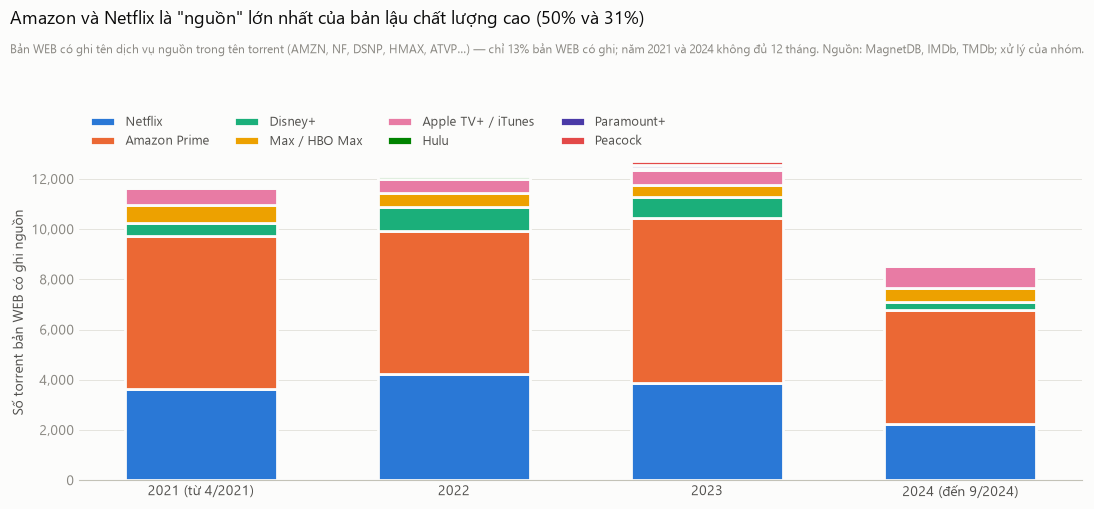

In [5]:
SVC = [("Netflix", r"(?i)\bnf\b|netflix"), ("Amazon Prime", r"(?i)\bamzn\b|amazon"), ("Disney+", r"(?i)\bdsnp\b|disney\+?\b"),
       ("Max / HBO Max", r"(?i)\bhmax\b|\bmax\b(?!\w)"), ("Apple TV+ / iTunes", r"(?i)\batvp\b|itunes|\bit\b(?=.*web)"),
       ("Hulu", r"(?i)\bhulu\b"), ("Paramount+", r"(?i)\bpmtp\b|paramount\+"), ("Peacock", r"(?i)\bpcok\b|peacock")]
web = ok[ok["quality_tier"] == "web"].copy()
web["svc"] = tag(web["name"], SVC)
tagged = web.dropna(subset=["svc"])
yr = pd.crosstab(tagged["ts"].dt.year, tagged["svc"])
yr = yr[[s for s, _ in SVC if s in yr.columns]]
share_tag = web["svc"].notna().mean()
fig, ax = plt.subplots(figsize=(11, 5.2))
V.style_axes(ax, grid="y")
bottom = np.zeros(len(yr))
x = np.arange(len(yr))
for (svc, _), c in zip(SVC, V.CAT):
    if svc not in yr.columns:
        continue
    ax.bar(x, yr[svc], bottom=bottom, color=c, edgecolor=V.SURFACE, linewidth=2, width=0.6, label=svc)
    bottom += yr[svc].values
ax.set_xticks(x)
ax.set_xticklabels([f"{y}{' (đến 9/2024)' if y == 2024 else ''}{' (từ 4/2021)' if y == 2021 else ''}" for y in yr.index], color=V.INK2)
ax.yaxis.set_major_formatter(FuncFormatter(V.fmt_int))
ax.set_ylabel("Số torrent bản WEB có ghi nguồn")
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, 1.12))
top_svc = tagged["svc"].value_counts(normalize=True)
V.titles(fig, f"Amazon và Netflix là \"nguồn\" lớn nhất của bản lậu chất lượng cao ({top_svc.iloc[0]:.0%} và {top_svc.iloc[1]:.0%})",
         f"Bản WEB có ghi tên dịch vụ nguồn trong tên torrent (AMZN, NF, DSNP, HMAX, ATVP…) — chỉ {share_tag:.0%} bản WEB có ghi; "
         f"năm 2021 và 2024 không đủ 12 tháng. {SRC}", extra=0.2)
V.save(fig, FOLDER, "05_streaming_rip_sources")

**Nhận xét.** Trong các bản WEB có ghi nguồn, **Amazon (~50%)** và **Netflix (~31%)** chiếm áp đảo, rồi Disney+, Max, Apple TV+/iTunes. Điều này khớp với phần 1.3: Prime Video và Netflix có kho phim và độ phủ toàn cầu lớn nhất — **nền tảng càng lớn càng là nguồn rip lớn**. Lưu ý chỉ ~13% bản WEB có ghi tên dịch vụ.

## 6. Phim nước nào được "bản địa hóa" cho cộng đồng nào?

  wrote plots\8_piracy_ecosystem\06_dubbing_heatmap.png


WindowsPath('D:/dulieulon/plots/8_piracy_ecosystem/06_dubbing_heatmap.png')

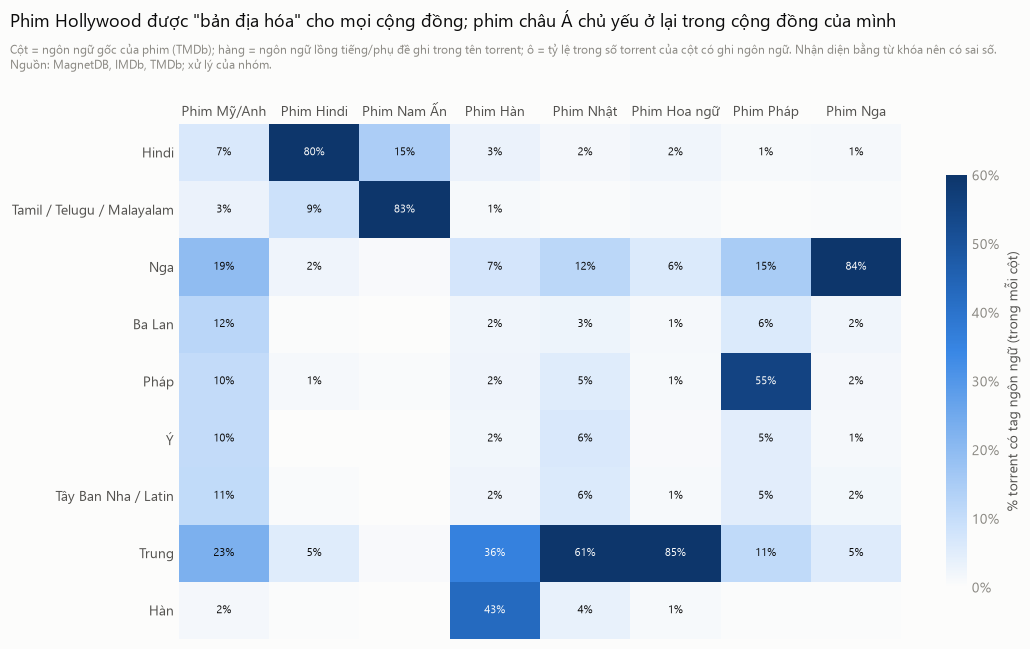

In [6]:
DUB = [("Hindi", r"(?i)hindi"), ("Tamil / Telugu / Malayalam", r"(?i)tamil|telugu|malayalam|kannada"),
       ("Nga", r"(?i)[а-яё]|\brus\b"), ("Ba Lan", r"(?i)\bpl\b|lektor|dubbing\.pl|napisy"),
       ("Pháp", r"(?i)\bfrench\b|truefrench|\bvff\b|\bvfq\b|\bmulti\b"), ("Ý", r"(?i)\bita\b|italian"),
       ("Tây Ban Nha / Latin", r"(?i)latino|castellano|dual.?lat|spanish|\besp\b"), ("Bồ Đào Nha (BR)", r"(?i)dublado|pt-br|\bpt\b"),
       ("Đức", r"(?i)\bgerman\b|\bger\b"), ("Trung", r"[一-鿿]"), ("Hàn", r"(?i)[가-힣]|korean"),
       ("Thổ Nhĩ Kỳ", r"(?i)turkish|\btr\b")]
ok["dub"] = tag(ok["name"], DUB)
LANGS = [("en", "Phim Mỹ/Anh"), ("hi", "Phim Hindi"), ("te,ta,ml,kn", "Phim Nam Ấn"), ("ko", "Phim Hàn"),
         ("ja", "Phim Nhật"), ("zh,cn", "Phim Hoa ngữ"), ("fr", "Phim Pháp"), ("ru", "Phim Nga")]
lang_map = {c: lbl for codes, lbl in LANGS for c in codes.split(",")}
ok["orig"] = ok["original_language"].map(lang_map)
sub = ok.dropna(subset=["dub", "orig"])
mat = pd.crosstab(sub["dub"], sub["orig"], normalize="columns").reindex(index=[d for d, _ in DUB],
                                                                     columns=[l for _, l in LANGS]).fillna(0)
mat = mat[mat.max(axis=1) >= 0.02]                   # bỏ hàng gần như trống (vd. Đức, Thổ Nhĩ Kỳ)
fig, ax = plt.subplots(figsize=(11, 6.6))
im = ax.imshow(mat.values, cmap=V.SEQ, aspect="auto", vmin=0, vmax=min(0.6, mat.values.max()))
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        if v >= 0.01:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                    color=V.SURFACE if v > 0.3 else V.INK)
ax.set_xticks(range(mat.shape[1]))
ax.set_xticklabels(mat.columns, color=V.INK2)
ax.xaxis.tick_top()
ax.set_yticks(range(mat.shape[0]))
ax.set_yticklabels(mat.index, color=V.INK2)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.outline.set_visible(False)
cb.set_label("% torrent có tag ngôn ngữ (trong mỗi cột)", color=V.INK2)
cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
V.titles(fig, "Phim Hollywood được \"bản địa hóa\" cho mọi cộng đồng; phim châu Á chủ yếu ở lại trong cộng đồng của mình",
         f"Cột = ngôn ngữ gốc của phim (TMDb); hàng = ngôn ngữ lồng tiếng/phụ đề ghi trong tên torrent; ô = tỷ lệ trong số torrent "
         f"của cột có ghi ngôn ngữ. Nhận diện bằng từ khóa nên có sai số. {SRC}")
V.save(fig, FOLDER, "06_dubbing_heatmap")

**Nhận xét.** **Phim Mỹ/Anh** được lồng tiếng/phụ đề cho **mọi** cộng đồng (Trung 23%, Nga 19%, Ba Lan 12%, Tây Ban Nha 11%, Pháp, Ý ~10%). Ngược lại, phim châu Á **chủ yếu ở lại trong cộng đồng của mình**: 80% torrent phim Hindi có tag Hindi, 83% phim Nam Ấn có tag Tamil/Telugu/Malayalam, 85% phim Hoa ngữ có chữ Hán. Phim Hàn, Nhật được cộng đồng Trung Quốc chia sẻ nhiều (36%, 61%) — dấu vết của làn sóng Hallyu và anime.

## 7. Các trang lậu Nam Á hoạt động thế nào?

  wrote plots\8_piracy_ecosystem\07_south_asia_sites.png


WindowsPath('D:/dulieulon/plots/8_piracy_ecosystem/07_south_asia_sites.png')

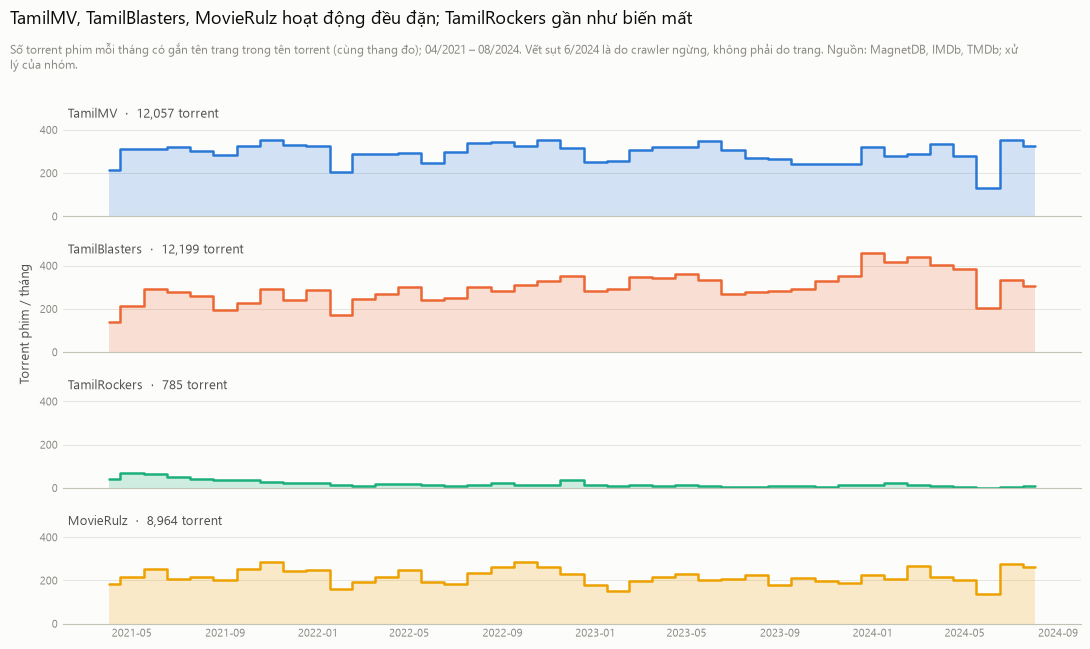

In [7]:
SITES = [("TamilMV", r"(?i)tamilmv"), ("TamilBlasters", r"(?i)tamilblasters"), ("TamilRockers", r"(?i)tamilrockers"),
         ("MovieRulz", r"(?i)movierulz")]
ok["site"] = tag(ok["name"], SITES)
ms = ok.dropna(subset=["site"]).assign(m=lambda d: d["ts"].dt.to_period("M").dt.to_timestamp())
ms = ms.groupby(["m", "site"]).size().unstack(fill_value=0)
ms = ms[ms.index < "2024-09-01"]
fig, axes = plt.subplots(len(SITES), 1, figsize=(11, 6.6), sharex=True)
for ax, (s, _), c in zip(axes, SITES, V.CAT):
    V.style_axes(ax)
    y = ms[s] if s in ms.columns else pd.Series(0, index=ms.index)
    ax.fill_between(y.index, y.values, color=c, alpha=0.2, linewidth=0, step="mid")
    ax.step(y.index, y.values, color=c, where="mid", linewidth=1.8)
    ax.text(0.005, 0.95, f"{s}  ·  {int(y.sum()):,} torrent", transform=ax.transAxes, va="top", color=V.INK2, fontsize=9)
    ax.set_ylim(0, ms.values.max() * 1.15)
    ax.tick_params(labelsize=8)
fig.supylabel("Torrent phim / tháng", color=V.INK2, fontsize=9)
V.titles(fig, "TamilMV, TamilBlasters, MovieRulz hoạt động đều đặn; TamilRockers gần như biến mất",
         f"Số torrent phim mỗi tháng có gắn tên trang trong tên torrent (cùng thang đo); 04/2021 – 08/2024. "
         f"Vết sụt 6/2024 là do crawler ngừng, không phải do trang. {SRC}")
V.save(fig, FOLDER, "07_south_asia_sites")

**Nhận xét.** **TamilMV, TamilBlasters, MovieRulz** đăng đều đặn 200–450 torrent phim mỗi tháng suốt 3 năm dù liên tục bị chặn tên miền (tên trang trong torrent đổi đuôi: `.tc`, `.cz`, `.win`…). **TamilRockers** — từng là trang nổi tiếng nhất — gần như biến mất. Vết sụt 6/2024 là do crawler ngừng, không phải do các trang.

## 8. Torrent giả trông như thế nào?

  wrote plots\8_piracy_ecosystem\08_fake_torrents.png


WindowsPath('D:/dulieulon/plots/8_piracy_ecosystem/08_fake_torrents.png')

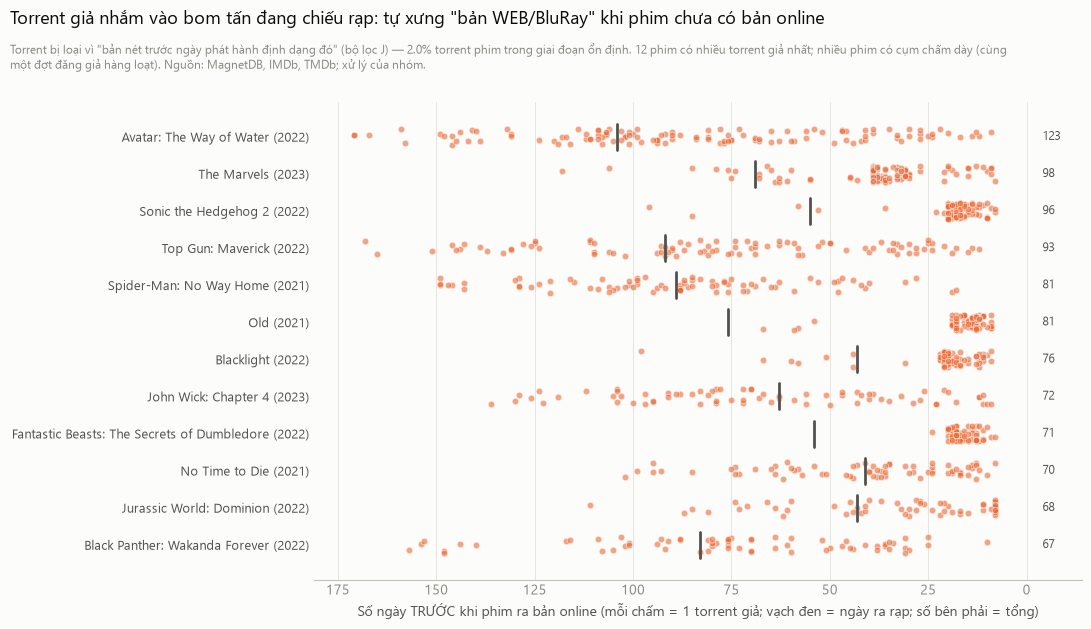

In [8]:
# Mốc so sánh = ngày ra bản online (Digital) sớm nhất: torrent giả chủ yếu là bản tự xưng "WEB/BluRay"
# xuất hiện khi phim mới CHỈ chiếu rạp. Vạch đứng trên mỗi hàng = ngày phim ra rạp.
dates = duckdb.sql(f"SELECT imdb_id, first_digital, first_theatrical FROM read_parquet('{P('tmdb_movies.parquet')}')").df()
fake = t[t["implausible"]].merge(dates, on="imdb_id", how="left").dropna(subset=["first_digital"])
fake["days_before_digital"] = (fake["first_digital"] - fake["ts"].dt.normalize()).dt.days
topf = fake["imdb_id"].value_counts().head(12).index
ff = fake[fake["imdb_id"].isin(topf)]
order = ff.groupby("imdb_id").size().sort_values().index
names = ff.drop_duplicates("imdb_id").set_index("imdb_id")
fig, ax = plt.subplots(figsize=(11, 6.4))
V.style_axes(ax, grid="x")
rng = np.random.default_rng(1)
xmax = min(ff["days_before_digital"].max() + 10, 200)
for i, iid in enumerate(order):
    rows = ff[ff["imdb_id"] == iid]
    ax.scatter(rows["days_before_digital"].clip(upper=xmax), i + rng.uniform(-0.22, 0.22, len(rows)), s=22,
               color=V.ORANGE, alpha=0.6, edgecolor=V.SURFACE, linewidth=0.6, zorder=3)
    th = (names.loc[iid, "first_digital"] - names.loc[iid, "first_theatrical"]).days
    if pd.notna(th) and 0 <= th <= xmax:
        ax.plot([th, th], [i - 0.35, i + 0.35], color=V.INK2, linewidth=2, zorder=4)
    ax.text(-4, i, f"{len(rows)}", va="center", ha="left", color=V.INK2, fontsize=8.5)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{names.loc[i, 'title']} ({names.loc[i, 'start_year']})" for i in order], color=V.INK2, fontsize=9)
ax.set_xlim(xmax, -14)
ax.set_xlabel("Số ngày TRƯỚC khi phim ra bản online (mỗi chấm = 1 torrent giả; vạch đen = ngày ra rạp; số bên phải = tổng)")
share_fake = t["implausible"].mean()
V.titles(fig, "Torrent giả nhắm vào bom tấn đang chiếu rạp: tự xưng \"bản WEB/BluRay\" khi phim chưa có bản online",
         f"Torrent bị loại vì \"bản nét trước ngày phát hành định dạng đó\" (bộ lọc J) — {share_fake:.1%} torrent phim trong giai đoạn "
         f"ổn định. 12 phim có nhiều torrent giả nhất; nhiều phim có cụm chấm dày (cùng một đợt đăng giả hàng loạt). {SRC}")
V.save(fig, FOLDER, "08_fake_torrents")

**Nhận xét.** Torrent giả (2% torrent phim) nhắm vào **bom tấn đang chiếu rạp**: tự xưng "WEB-DL" hay "BluRay" khi phim **chưa có bản online** (vạch đen = ngày ra rạp; nhiều chấm còn xuất hiện cả *trước* ngày ra rạp). Nhiều phim có **cụm chấm dày** — một đợt đăng hàng loạt cùng lúc (vd. *Old*, *Fantastic Beasts*, *Sonic 2*), dấu hiệu của spam/mã độc tự động. Đây là lý do bộ lọc J được thêm vào quy trình làm sạch.

## Tóm tắt phần 3.3

| Khía cạnh | Phát hiện chính |
|---|---|
| Nhà phát hành | RARBG, YTS thống trị; RARBG đóng cửa 5/2023 để lại khoảng trống không ai lấp hết |
| Công nghệ | x265 tăng dần, AV1 xuất hiện; 4K tăng gấp ba, 1080p là chuẩn |
| Nguồn rip | Amazon và Netflix chiếm ~80% bản WEB có ghi nguồn |
| Ngôn ngữ | Phim Hollywood được bản địa hóa cho mọi cộng đồng; phim châu Á ở lại trong cộng đồng |
| Nam Á | Các trang lậu sống dai dù bị chặn tên miền |
| Torrent giả | ~2%, nhắm vào bom tấn đang chiếu rạp, thường đăng hàng loạt |